#**Q2. Drawdown Analysis**

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

df = pd.read_csv('Ind_CSI_HSI.csv')
df['datadate'] = pd.to_datetime(df['datadate'])
mask = (df['datadate'] >= '2006-01-01') & (df['datadate'] <= '2025-12-01')
df = df[mask].copy()
df = df.sort_values('datadate').reset_index(drop=True)
csi_gvkey = 153435
hsi_gvkey = 150051
csi_prices = df[df['gvkeyx'] == csi_gvkey]['prccd'].values
hsi_prices = df[df['gvkeyx'] == hsi_gvkey]['prccd'].values
min_len = min(len(csi_prices), len(hsi_prices))
csi_prices = csi_prices[:min_len]
hsi_prices = hsi_prices[:min_len]
dates = df['datadate'].unique()[:min_len]

#daily returns
csi_returns = np.diff(csi_prices) / csi_prices[:-1]
hsi_returns = np.diff(hsi_prices) / hsi_prices[:-1]
returns_dates = dates[1:]

**(a) Historical and Gaussian $\text{VaR}_{0.05}$ and Corresponding ES ($1 million total investment)**

In [ ]:
def historical_var(returns, confidence=0.05):
    return np.percentile(returns, confidence * 100)

def historical_es(returns, confidence=0.05):
    var = historical_var(returns, confidence)
    return returns[returns <= var].mean()

def gaussian_var(returns, confidence=0.05, investment=1): #Gaussian VaR = -(mu + sigma * Z_alpha) * I
    mu = returns.mean()
    sigma = returns.std()
    Z_alpha = norm.ppf(confidence)
    return (mu + sigma * Z_alpha) * investment

def gaussian_es(returns, confidence=0.05, investment=1): #Gaussian ES = -(mu + sigma * pdf(Z_alpha)/alpha) * I
    mu = returns.mean()
    sigma = returns.std()
    alpha = confidence
    Z_alpha = norm.ppf(alpha)
    pdf_val = norm.pdf(Z_alpha)
    return -(mu + sigma * pdf_val / alpha) * investment

In [ ]:
investment = 1_000_000

#csi 300
csi_hist_var = historical_var(csi_returns) * investment
csi_hist_es = historical_es(csi_returns) * investment
csi_gauss_var = gaussian_var(csi_returns, investment=investment)
csi_gauss_es = gaussian_es(csi_returns, investment=investment)

#hsi
hsi_hist_var = historical_var(hsi_returns) * investment
hsi_hist_es = historical_es(hsi_returns) * investment
hsi_gauss_var = gaussian_var(hsi_returns, investment=investment)
hsi_gauss_es = gaussian_es(hsi_returns, investment=investment)

print(f"{'Index':<10} {'Method':<12} {'VaR (5%)':<15} {'ES (5%)':<15}")
print(f"{'CSI 300':<10} {'Historical':<12} ${csi_hist_var:,.0f}     ${csi_hist_es:,.0f}")
print(f"{'CSI 300':<10} {'Gaussian':<12} ${csi_gauss_var:,.0f}     ${csi_gauss_es:,.0f}")
print(f"{'HSI':<10} {'Historical':<12} ${hsi_hist_var:,.0f}     ${hsi_hist_es:,.0f}")
print(f"{'HSI':<10} {'Gaussian':<12} ${hsi_gauss_var:,.0f}     ${hsi_gauss_es:,.0f}")

Index      Method       VaR (5%)        ES (5%)        
CSI 300    Historical   $-23,458     $-39,122
CSI 300    Gaussian     $-25,004     $-32,321
HSI        Historical   $-22,556     $-33,842
HSI        Gaussian     $-24,089     $-30,698


**(b) Historical and Gaussian $\text{VaR}_{0.05}$ and Corresponding ES (equal allocation, no rebalancing)**


In [ ]:
initial_investment = 1_000_000
initial_csi_shares = (0.5 * initial_investment) / csi_prices[0]
initial_hsi_shares = (0.5 * initial_investment) / hsi_prices[0]

#portfolio value
portfolio_values = initial_csi_shares * csi_prices + initial_hsi_shares * hsi_prices
portfolio_returns = np.diff(portfolio_values) / portfolio_values[:-1]

#VaR and ES
port_hist_var = historical_var(portfolio_returns) * initial_investment
port_hist_es = historical_es(portfolio_returns) * initial_investment
port_gauss_var = gaussian_var(portfolio_returns, investment=initial_investment)
port_gauss_es = gaussian_es(portfolio_returns, investment=initial_investment)

print(f"\n{'Portfolio':<10} {'Method':<12} {'VaR (5%)':<15} {'ES (5%)':<15}")
print(f"{'50/50':<10} {'Historical':<12} ${port_hist_var:,.0f}     ${port_hist_es:,.0f}")
print(f"{'50/50':<10} {'Gaussian':<12} ${port_gauss_var:,.0f}     ${port_gauss_es:,.0f}")


Portfolio  Method       VaR (5%)        ES (5%)        
50/50      Historical   $-21,309     $-34,198
50/50      Gaussian     $-21,901     $-28,196


Comparison:

In [ ]:
print("Diversification Benefit (Historical VaR)")
sum_hist_var = csi_hist_var + hsi_hist_var
reduction_hist = sum_hist_var - port_hist_var
pct_hist = (reduction_hist / abs(sum_hist_var)) * 100
print(f"Sum of individual VaRs: ${sum_hist_var:>10,.0f}")
print(f"Portfolio VaR:          ${port_hist_var:>10,.0f}")
print(f"Reduction:              ${reduction_hist:>10,.0f} ({pct_hist:.1f}%)\n")

print("Diversification Benefit (Gaussian VaR)")
sum_gauss_var = csi_gauss_var + hsi_gauss_var
reduction_gauss = sum_gauss_var - port_gauss_var
pct_gauss = (reduction_gauss / abs(sum_gauss_var)) * 100
print(f"Sum of individual VaRs: ${sum_gauss_var:>10,.0f}")
print(f"Portfolio VaR:          ${port_gauss_var:>10,.0f}")
print(f"Reduction:              ${reduction_gauss:>10,.0f} ({pct_gauss:.1f}%)\n")

print("Comparison: Historical VaR vs Gaussian VaR")
print(f"{'':<25} {'Historical':<12} {'Gaussian':<12} {'Difference':<15}")
print(f"{'CSI 300 VaR:':<25} ${csi_hist_var:>10,.0f}   ${csi_gauss_var:>10,.0f}   ${csi_gauss_var - csi_hist_var:>10,.0f}")
print(f"{'CSI 300 ES:':<25} ${csi_hist_es:>10,.0f}   ${csi_gauss_es:>10,.0f}   ${csi_gauss_es - csi_hist_es:>10,.0f}")
print()
print(f"{'HSI VaR:':<25} ${hsi_hist_var:>10,.0f}   ${hsi_gauss_var:>10,.0f}   ${hsi_gauss_var - hsi_hist_var:>10,.0f}")
print(f"{'HSI ES:':<25} ${hsi_hist_es:>10,.0f}   ${hsi_gauss_es:>10,.0f}   ${hsi_gauss_es - hsi_hist_es:>10,.0f}")
print()
print(f"{'Portfolio VaR:':<25} ${port_hist_var:>10,.0f}   ${port_gauss_var:>10,.0f}   ${port_gauss_var - port_hist_var:>10,.0f}")
print(f"{'Portfolio ES:':<25} ${port_hist_es:>10,.0f}   ${port_gauss_es:>10,.0f}   ${port_gauss_es - port_hist_es:>10,.0f}")


Diversification Benefit (Historical VaR)
Sum of individual VaRs: $   -46,014
Portfolio VaR:          $   -21,309
Reduction:              $   -24,705 (-53.7%)

Diversification Benefit (Gaussian VaR)
Sum of individual VaRs: $   -49,093
Portfolio VaR:          $   -21,901
Reduction:              $   -27,192 (-55.4%)

Comparison: Historical VaR vs Gaussian VaR
                          Historical   Gaussian     Difference     
CSI 300 VaR:              $   -23,458   $   -25,004   $    -1,546
CSI 300 ES:               $   -39,122   $   -32,321   $     6,801

HSI VaR:                  $   -22,556   $   -24,089   $    -1,533
HSI ES:                   $   -33,842   $   -30,698   $     3,144

Portfolio VaR:            $   -21,309   $   -21,901   $      -592
Portfolio ES:             $   -34,198   $   -28,196   $     6,002


**1. Individual Indices vs. Portfolio (Historical Method)** <br>
The portfolio historical VaR (-21,309) is less negative than both individual VaRs (-23,458 and -22,556), and is better than the sum of individuals VaRs (-46,014). Portfolio historical ES (-34,198) is between CSI 300 historical ES (-39,122) and HSI historical ES (-33,842). In conclusion, historical VaR shows strong diversification benefit, as the portfolio loses less in the worst 5% of days than either index alone. The diversification reduced VaR by 53.7%.

**2. Individual Indices vs. Portfolio (Gaussian Method)** <br>
The portfolio Gaussian VaR (-21,901) is less negative than both individual Gaussian VaRs (-25,004 and -24,089), and is better than the sum of both Gaussian VaRs (-49,093). The portfolio Gaussian ES (-28,196) is also less negative than both individual ES values (-32,321 and -30,698). Consistent with the historical method, the Gaussian VaR also shows diversificiation benefits with a reduction of 55.4%.

**3. Historical vs. Gaussian Comparison** <br>
Gaussian VaR is more conservative (incurs larger loss) than historical VaR for CSI 300, HSI, and the portfolio. However, Gaussian ES is less conservative (incurs smaller loss) than historical ES, which suggests that returns have fatter tails than normal distribution, as historical ES captures extreme tail losses better.

**(c) Calculating and Plotting Drawdowns for the Two Indices**

In [ ]:
def calculate_drawdowns(prices):
    running_max = np.maximum.accumulate(prices)
    drawdowns = (prices - running_max) / running_max
    return drawdowns

def find_longest_drawdown_period(drawdowns, dates):
    is_dd = drawdowns < -0.2 #tighten the boundary
    changes = np.diff(np.concatenate(([0], is_dd.astype(int), [0])))
    start_idx = np.where(changes == 1)[0]
    end_idx = np.where(changes == -1)[0]

    if len(start_idx) == 0:
        return None, 0, None, None

    durations = end_idx - start_idx
    longest_idx = np.argmax(durations)
    longest_start = start_idx[longest_idx]
    longest_end = end_idx[longest_idx] - 1

    return (
        longest_start,
        longest_end,
        durations[longest_idx],
        dates[longest_start],
        dates[longest_end]
        )

In [ ]:
csi_dd = calculate_drawdowns(csi_prices)
hsi_dd = calculate_drawdowns(hsi_prices)
csi_max_dd = csi_dd.min()
hsi_max_dd = hsi_dd.min()
csi_max_dd_date = dates[np.argmin(csi_dd)]
hsi_max_dd_date = dates[np.argmin(hsi_dd)]
csi_start, csi_end, csi_duration, csi_start_date, csi_end_date = find_longest_drawdown_period(csi_dd, dates)
hsi_start, hsi_end, hsi_duration, hsi_start_date, hsi_end_date = find_longest_drawdown_period(hsi_dd, dates)
print(f"\n{'Index':<10} {'Metric':<25} {'Value':<20}")
print(f"{'CSI 300':<10} {'Maximum Drawdown':<25} {csi_max_dd*100:.2f}%")
print(f"{'CSI 300':<10} {'Max DD Date':<25} {csi_max_dd_date.strftime('%Y-%m-%d')}")
print(f"{'CSI 300':<10} {'Longest DD (trading days)':<25} {csi_duration}")
print(f"{'CSI 300':<10} {'Longest DD period':<25} {csi_start_date.strftime('%Y-%m-%d')} to {csi_end_date.strftime('%Y-%m-%d')}")
print(f"\n{'HSI':<10} {'Maximum Drawdown':<25} {hsi_max_dd*100:.2f}%")
print(f"{'HSI':<10} {'Max DD Date':<25} {hsi_max_dd_date.strftime('%Y-%m-%d')}")
print(f"{'HSI':<10} {'Longest DD (trading days)':<25} {hsi_duration}")
print(f"{'HSI':<10} {'Longest DD period':<25} {hsi_start_date.strftime('%Y-%m-%d')} to {hsi_end_date.strftime('%Y-%m-%d')}")


Index      Metric                    Value               
CSI 300    Maximum Drawdown          -72.30%
CSI 300    Max DD Date               2008-11-04
CSI 300    Longest DD (trading days) 1861
CSI 300    Longest DD period         2008-03-04 to 2015-04-21

HSI        Maximum Drawdown          -65.18%
HSI        Max DD Date               2008-10-27
HSI        Longest DD (trading days) 1639
HSI        Longest DD period         2008-05-22 to 2014-09-02


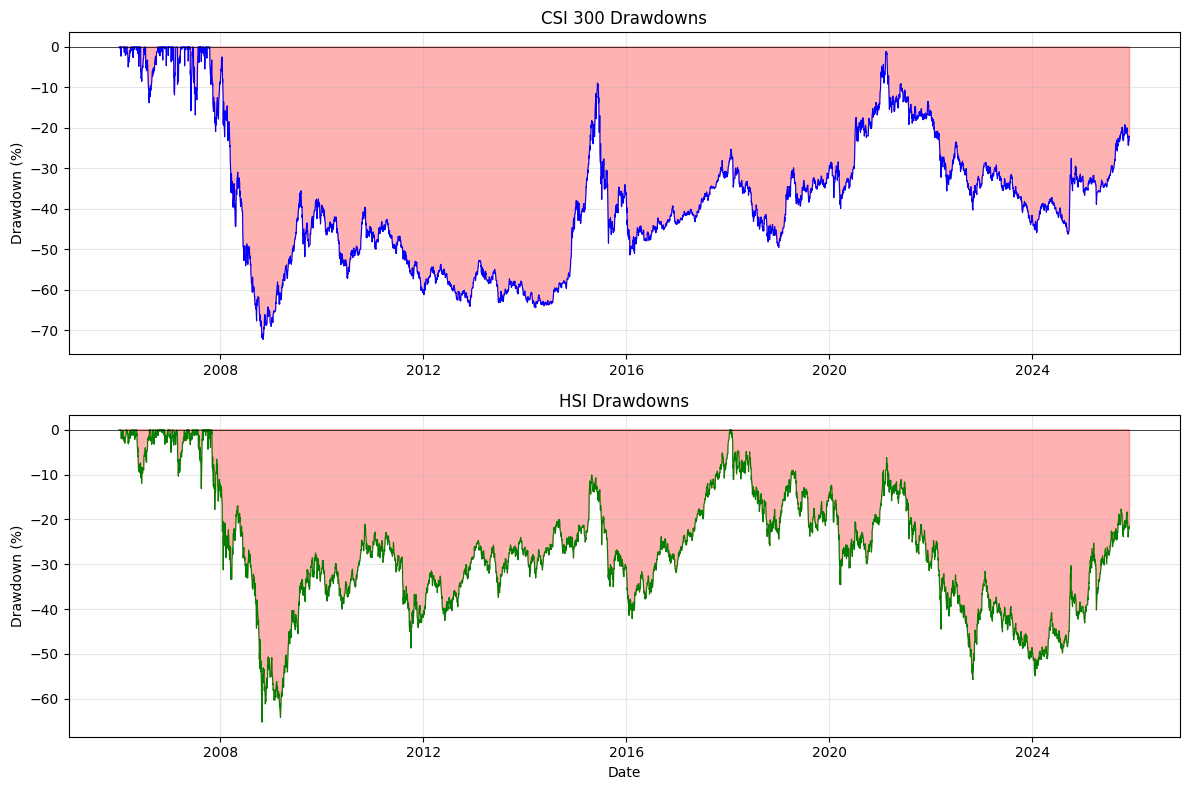

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

axes[0].plot(dates, csi_dd * 100, 'b-', linewidth=0.8)
axes[0].fill_between(dates, csi_dd * 100, 0, where=csi_dd < 0, color='red', alpha=0.3)
axes[0].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[0].set_title('CSI 300 Drawdowns', fontsize=12)
axes[0].set_ylabel('Drawdown (%)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(dates, hsi_dd * 100, 'g-', linewidth=0.8)
axes[1].fill_between(dates, hsi_dd * 100, 0, where=hsi_dd < 0, color='red', alpha=0.3)
axes[1].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
axes[1].set_title('HSI Drawdowns', fontsize=12)
axes[1].set_ylabel('Drawdown (%)')
axes[1].set_xlabel('Date')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**(d) Calculating Portfolio Drawdown**

In [ ]:
port_dd = calculate_drawdowns(portfolio_values)
port_max_dd = port_dd.min()
port_max_dd_date = returns_dates[np.argmin(port_dd[1:])]
port_start, port_end, port_duration, port_start_date, port_end_date = find_longest_drawdown_period(port_dd, dates)
print(f"\n{'Portfolio':<15} {'Metric':<25} {'Value':<20}")
print(f"{'50/50 Portfolio':<15} {'Maximum Drawdown':<25} {port_max_dd*100:.2f}%")
print(f"{'50/50 Portfolio':<15} {'Max DD Date':<25} {port_max_dd_date.strftime('%Y-%m-%d')}")
print(f"{'50/50 Portfolio':<15} {'Longest DD (trading days)':<25} {port_duration}")
print(f"{'50/50 Portfolio':<15} {'Longest DD period':<25} {port_start_date.strftime('%Y-%m-%d')} to {port_end_date.strftime('%Y-%m-%d')}")


Portfolio       Metric                    Value               
50/50 Portfolio Maximum Drawdown          -69.53%
50/50 Portfolio Max DD Date               2008-10-27
50/50 Portfolio Longest DD (trading days) 1854
50/50 Portfolio Longest DD period         2008-03-04 to 2015-04-10


Comparison:

In [ ]:
comparison_data = {
    'Index': ['CSI 300', 'HSI', 'Portfolio (50/50)'],
    'Max Drawdown (%)': [csi_max_dd*100, hsi_max_dd*100, port_max_dd*100],
    'Longest DD (days)': [csi_duration, hsi_duration, port_duration]
}

comparison_df = pd.DataFrame(comparison_data)
print("\n", comparison_df.to_string(index=False))


             Index  Max Drawdown (%)  Longest DD (days)
          CSI 300        -72.303845               1861
              HSI        -65.181859               1639
Portfolio (50/50)        -69.529459               1854


Judging from maximum drawdown, CSI300 is the most severe, followed by the portfolio, and HSI has least maximum drawdown. From the longest drawdown duration, CSI 300 takes the longest to recover, followed by the portfolio, then HSI. This observation shows that diversification helps with the duration of the drawdown but not its severity. Compared to CSI 300, the portfolio reduces the duration of drawdown by only 7 days, but its maximum drawdown is closer to the worse index. Between the three indices, CSI is the worst in both metrics, while HSI is more resilient. The portfolio performs in between the the two indices for both metrics, although not much different.

HSI is the least risky investment, with the lowest VaR and ES, smallest maximum drawdown, and the shortest recovery period. CSI 300 is the most risky with the highest VaR and ES, largest max drawdown, and the longest recovery.

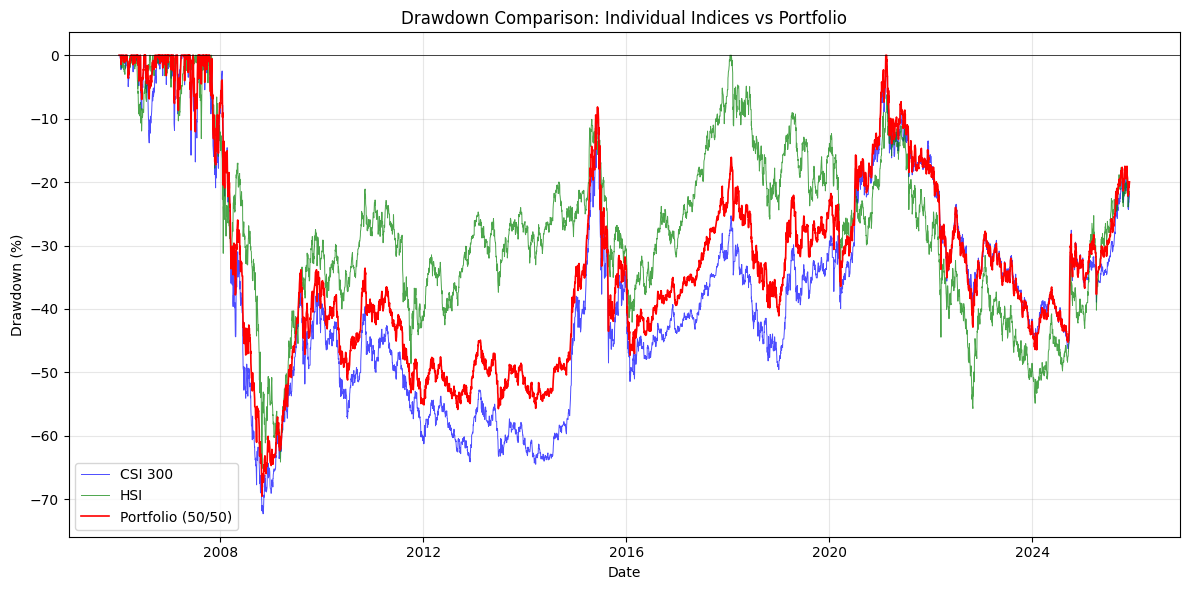

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(dates, csi_dd * 100, 'b-', linewidth=0.7, alpha=0.7, label='CSI 300')
ax.plot(dates, hsi_dd * 100, 'g-', linewidth=0.7, alpha=0.7, label='HSI')
ax.plot(dates, port_dd * 100, 'r-', linewidth=1.2, label='Portfolio (50/50)')
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax.set_title('Drawdown Comparison: Individual Indices vs Portfolio', fontsize=12)
ax.set_ylabel('Drawdown (%)')
ax.set_xlabel('Date')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#**Q3. Co-drawdown Analysis**

**(a) Identifying, Plotting, and Calculating Probability of Co-drawdown and Any-drawdown**

In [46]:
#identifying periods of cdd and add
csi_in_dd = csi_dd < 0
hsi_in_dd = hsi_dd < 0
co_dd = csi_in_dd & hsi_in_dd #co-drawdown
any_dd = csi_in_dd | hsi_in_dd #any-drawdown

threshold = -0.2
csi_deep_dd = csi_dd < threshold
hsi_deep_dd = hsi_dd < threshold
co_deep_dd = csi_deep_dd & hsi_deep_dd

total_days = len(dates)
co_dd_days = co_dd.sum()
any_dd_days = any_dd.sum()
csi_dd_days = csi_in_dd.sum()
hsi_dd_days = hsi_in_dd.sum()
co_deep_dd_days = co_deep_dd.sum()

def extract_periods(boolean_series, dates, min_gap_days=1):
  series_int = boolean_series.astype(int)
  diff = np.diff(np.concatenate(([0], series_int, [0])))
  start_idx = np.where(diff == 1)[0]
  end_idx = np.where(diff == -1)[0] -1
  if min_gap_days > 1 and len(start_idx) > 1:
        merged_starts = []
        merged_ends = []
        current_start = start_idx[0]
        current_end = end_idx[0]

        for i in range(1, len(start_idx)):
            if start_idx[i] - current_end <= min_gap_days:
                current_end = end_idx[i]
            else:
                merged_starts.append(current_start)
                merged_ends.append(current_end)
                current_start = start_idx[i]
                current_end = end_idx[i]

        merged_starts.append(current_start)
        merged_ends.append(current_end)

        start_idx = np.array(merged_starts)
        end_idx = np.array(merged_ends)

  periods = []
  for s, e in zip(start_idx, end_idx):
        periods.append({
            'start_date': dates[s],
            'end_date': dates[e],
            'start_idx': s,
            'end_idx': e,
            'duration_days': e - s + 1
        })

  return periods

co_periods = extract_periods(co_dd, dates, min_gap_days=5)
any_periods = extract_periods(any_dd, dates, min_gap_days=5)

#cdd
print("Co-Drawdown Periods:\n")
print(f"{'Period #':<10} {'Start Date':<15} {'End Date':<15} {'Duration (days)':<20}")

for i, period in enumerate(co_periods, 1):
    print(f"{i:<10} {period['start_date'].strftime('%Y-%m-%d'):<15} "
          f"{period['end_date'].strftime('%Y-%m-%d'):<15} {period['duration_days']:<20,}")

print(f"\nTotal co-drawdown periods: {len(co_periods)}")
print(f"Total co-drawdown days: {co_dd.sum():,}")

#add
print("\nAny-Drawdown Periods:\n")
print(f"{'Period #':<10} {'Start Date':<15} {'End Date':<15} {'Duration (days)':<20}")

for i, period in enumerate(any_periods, 1):
    print(f"{i:<10} {period['start_date'].strftime('%Y-%m-%d'):<15} "
          f"{period['end_date'].strftime('%Y-%m-%d'):<15} {period['duration_days']:<20,}")

print(f"\nTotal any-drawdown periods: {len(any_periods)}")
print(f"Total any-drawdown days: {any_dd.sum():,}")

Co-Drawdown Periods:

Period #   Start Date      End Date        Duration (days)     
1          2006-01-16      2006-01-18      3                   
2          2006-02-07      2006-02-22      12                  
3          2006-03-02      2006-03-31      22                  
4          2006-04-12      2006-04-14      3                   
5          2006-04-24      2006-04-27      4                   
6          2006-05-11      2006-10-12      111                 
7          2006-10-23      2006-10-30      6                   
8          2006-11-08      2006-11-14      5                   
9          2006-11-28      2006-11-28      1                   
10         2006-12-06      2006-12-11      4                   
11         2006-12-21      2006-12-21      1                   
12         2007-01-11      2007-02-13      24                  
13         2007-02-27      2007-03-21      17                  
14         2007-03-29      2007-03-30      2                   
15         2007-04

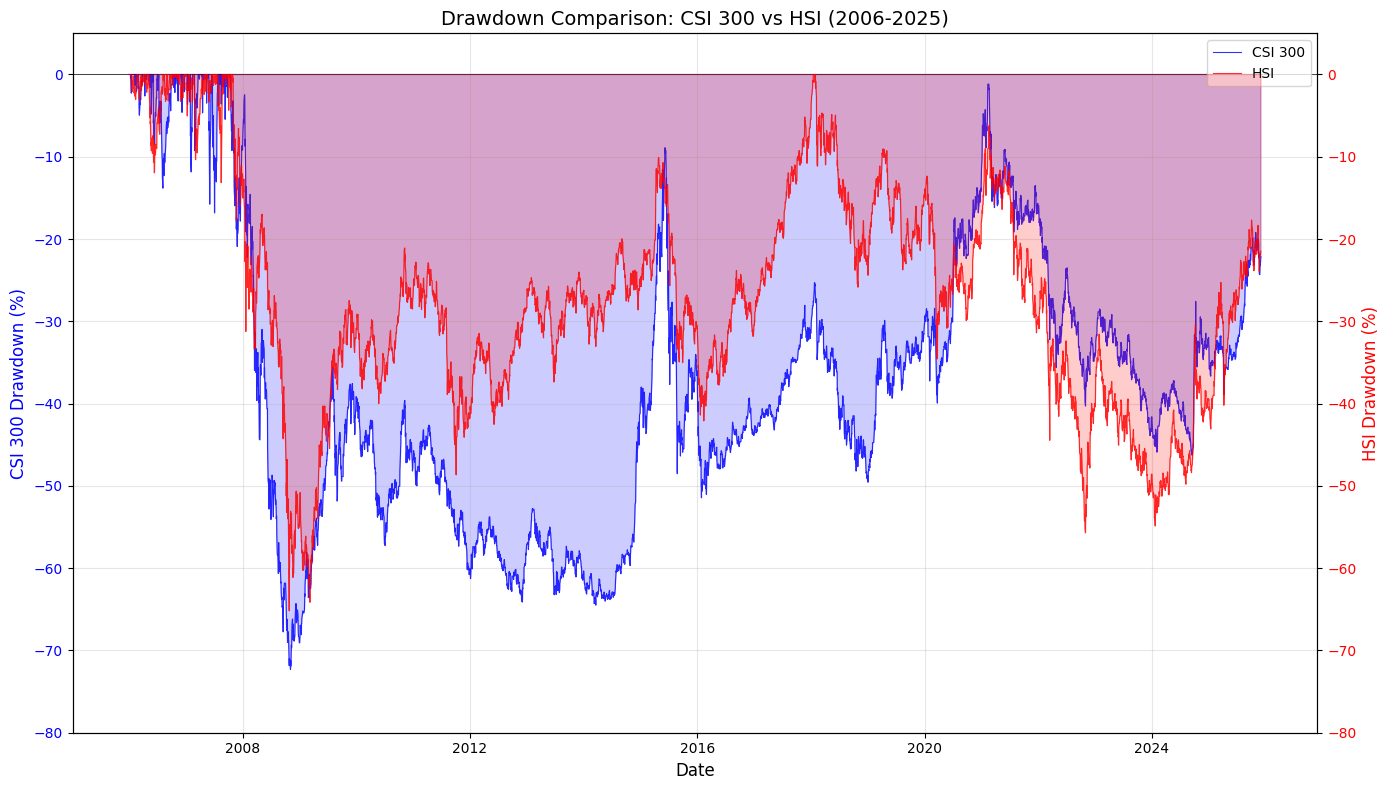

In [45]:
#visualize cdd and add

fig, ax1 = plt.subplots(figsize=(14, 8))

#csi300
ax1.plot(dates, csi_dd * 100, 'b-', linewidth=0.8, label='CSI 300', alpha=0.8)
ax1.fill_between(dates, csi_dd * 100, 0, where=csi_dd < 0, color='blue', alpha=0.2)
ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Date', fontsize=12)
ax1.set_ylabel('CSI 300 Drawdown (%)', color='blue', fontsize=12)
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_ylim(-80, 5)
ax1.grid(True, alpha=0.3)

#hsi
ax2 = ax1.twinx()
ax2.plot(dates, hsi_dd * 100, 'r-', linewidth=0.8, label='HSI', alpha=0.8)
ax2.fill_between(dates, hsi_dd * 100, 0, where=hsi_dd < 0, color='red', alpha=0.2)
ax2.set_ylabel('HSI Drawdown (%)', color='red', fontsize=12)
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(-80, 5)

plt.title('Drawdown Comparison: CSI 300 vs HSI (2006-2025)', fontsize=14)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')

plt.tight_layout()
plt.show()

In [59]:
#computing the probability of cdd
prob_csi = csi_deep_dd.sum() / total_days
prob_hsi = hsi_deep_dd.sum() / total_days
prob_unconditional = co_dd_days / total_days
prob_conditional = co_dd_days / any_dd_days
prob_tail_unconditional = co_deep_dd_days / total_days
prob_tail_conditional = co_deep_dd_days / any_dd_days #removes noise from tiny dips; -20% drop

print("Independent Probability of CSI Drawdown: ", prob_csi)
print("Independent Probability of HSI Drawdown: ", prob_hsi)
print("Unconditional Probability of Co-drawdown: ", prob_unconditional)
print("Conditional Probability of Co-drawdown: ", prob_conditional)
print("Unconditional Probability of Co-drawdown (<-20%): ", prob_tail_unconditional)
print("Conditional Probability of Co-drawdown (<-20%): ", prob_tail_conditional)

Independent Probability of CSI Drawdown:  0.8144726712856043
Independent Probability of HSI Drawdown:  0.73094688221709
Unconditional Probability of Co-drawdown:  0.9530408006158584
Conditional Probability of Co-drawdown:  0.9628621427182579
Unconditional Probability of Co-drawdown (<-20%):  0.6861046959199384
Conditional Probability of Co-drawdown (<-20%):  0.6931751895780672


Both unconditional and conditional probability of co-drawdowns indicate a strong correlation between CSI and HSI, as both indices are often in drawdown (shown by their independent probabilities). Due to this, both unconditional and conditional probabilities of co-drawdown are similar.

**(b) Identifying Co-drawdown Events and Implications on Diversification**

According to a typical interpretation of a co-drawdown duration, a co-drawdown of less than a month is considered just a minor noise. A co-drawdown of 20 - 60 days is considered a healthy correction period, and 60 - 120 days is considered a period of marker adjustment. A co-drawdown of 120 - 250 days typically indicates a significant downturn, while one that lasts over a year may indicate a crisis or structural issue.

From the calculations in Q3(a), the early sample (2006 - 2007) had short co-drawdown periods which are considered market noise, but there are 3 periods that stand out:


*   **2006-05-11 to 2006-10-12 (111 days):
Mid-2006 Global Market Correction**

This correction was driven by global risk-off sentiment, in relation to concerns about rising US interest rates and fears of inflation. At this time, China and Hong Kong were both classified as high-growth, high-risk markets, resulting as emerging market sell-off. Additionally, commodity price volatility at the time affected global growth expectations. This period is considered a natural, cyclical period of market correction.

*   **2007-10-12 to 2018-01-15 (2,677 days):
Global Financial Crisis, 2015 China Stock Market Crash**

This period is a mix of several market crises inclucing the Global Financial Crisis (2008), the European Debt Crisis, and the 2015 Chinese Stock Market Crash. Leading up to 2008, the Lehman brothers became heavily invested in mortgage-backed securutues and leveraged real estate assets. When the US housing bubble burst, these holdings rapidly lost value, leading to bankcruptcy and widespread panic in global credit markets. The 2015 Chinese Stock Market Crash was China's equity bubble burst, in which equity prices rapidly collapsed following a speculative boom in Chinese exchanges due to policy encouragement. Due to a mixture of effects from these events, both CSI and HSI fell and failed to recover to previous peaks, and since both indices are heavily correlated, co-drawdowns persisted for years.


*   **2018-01-25 to 2025-12-01 (2,048 days):
China-US Trade Wars, Hong Kong Protests, COVID-19**

This period is also caused by a mixture of global events including the China-US Trade War, Hong Kong Protests, the COVID-19 Pandemic, and the tightening of China regulatory tightening on technology and property sectors. Since HSI is heavily exposed to Chinese firms, and CSI 300 reflects China's domestic economy, the same economic shocks cause both indices to fall together. Persistent economic and political uncertainty, weak growth, and policy shocks cause markets to fail to regain prior peaks. This causes structural slowdown in the Chinese economy, as shown by lower growth post-2015, property sector stress, and regulatory tightening, which leads to long-lasting drawdowns.

**Implications on Diversification**

From these events, it can be seen that diversification has limited downside protection, as the other falls when one indice falls. During long periods of severe economic crises, diversification fails. Correlation between markets increases during stress, and both markets decline together. Diversification benefits can be seen in times without crises, as seen from the early periods (2006 - 2007), but is not reliable during major downturns. This shows that diversification may "diversify away" idiosyncratic risks under normal circumstances, but fails under systematic risk.

**(c) Probability of Daily Returns of the Two Indices Being Both Negative vs. Probability of Co-drawdown**

In [55]:
print(df.head())

   Unnamed: 0  gvkeyx   datadate     prccd
0        1305  150051 2006-01-02  14876.43
1        6777  153435 2006-01-02    923.45
2        6778  153435 2006-01-03    923.45
3        1306  150051 2006-01-03  14944.77
4        1307  150051 2006-01-04  15200.06


In [58]:
df = df.sort_values('datadate')
pivot = df.pivot(index='datadate', columns='gvkeyx', values='prccd')
pivot.columns = ['HSI', 'CSI']
returns = pivot.pct_change().dropna()
both_neg = (returns['HSI'] < 0) & (returns['CSI'] < 0)
prob_both_neg = both_neg.mean()
print("Probability both returns are negative:", prob_both_neg)

Probability both returns are negative: 0.2873917228103946


The probability that both indices have negative daily returns is significantly lower than the probability of co-drawdown (28.7% vs. 96.3% or 69.3%) because daily returns measure short-term price changes, while drawdowns represent a persistent state where prices remain below their historical peaks. Even if daily returns are positive, an index may still be in drawdown. Consequently, co-drawdowns occur much more frequently and last longer than simultaneous negative return days.